# Cơ sở lý thuyết
Support Vector Machine (SVM) là một thuật toán học máy có giám sát dùng để phân loại và phân tích hồi quy [1]. Một mô hình SVM là một cách biểu diễn các điểm trong không gian và lựa chọn ranh giới giữa hai thể loại sao cho khoảng cách từ các ví dụ luyện tập tới ranh giới là xa nhất có thể [2]. Để ứng dụng SVM giải quyết bài toán dự đoán phân loại đánh giá thời trang nữ, cần phân tích lựa chọn các đặc trưng liên quan đến bài toán đặt ra, đưa dữ liệu qua tiền xử lí và cuối cùng đưa dữ liệu vào thuật toán.

[1] [Huynh, C. T. (2020), Giới thiệu về Support Vector Machine](https://viblo.asia/p/gioi-thieu-ve-support-vector-machine-svm-6J3ZgPVElmB)

[2] [Wikipedia](https://vi.wikipedia.org/wiki/M%C3%A1y_vect%C6%A1_h%E1%BB%97_tr%E1%BB%A3)

# Thêm các thư viện cần thiết

In [10]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
import tqdm
import sys
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay, confusion_matrix

sns.set_theme(style="whitegrid")
%matplotlib inline

# Nhập dữ liệu

In [11]:
df1 = pd.read_csv('Womens Clothing E-Commerce Reviews.csv')
df = df1[['Review Text','Recommended IND','Class Name','Age']]
df1.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


# Tiền xử lý dữ liệu
Trước khi đưa dữ liệu vào model SVM, cần phải đưa dạng dữ liệu chữ ban đầu sang dạng dữ liệu số để model thực hiện học và dự đoán.
Trước tiên, với các mục có Review Text rỗng, ta điền chuỗi rỗng vào dòng đó. Sau đó, tạo một cột sentiment có giá trị True khi Recommend IND là 1.

In [12]:
df['Review Text'] = df['Review Text'].fillna('')

df['Sentiment'] = df['Recommended IND'] == 1
df.head()

,Review Text,Recommended IND,Class Name,Age,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,1,Intimates,33,True
1,Love this dress! it's sooo pretty. i happene...,1,Dresses,34,True
2,I had such high hopes for this dress and reall...,0,Dresses,60,False
3,"I love, love, love this jumpsuit. it's fun, fl...",1,Pants,50,True
4,This shirt is very flattering to all due to th...,1,Blouses,47,True


Tách dữ liệu thành hai phần: train và test.

In [13]:
# split data
train_data,test_data = train_test_split(df,train_size=0.8,random_state=0)
# select the columns and 
# prepare data for the models 

X_train_raw = train_data['Review Text']
y_train = train_data['Sentiment']
X_test_raw = test_data['Review Text']
y_test = test_data['Sentiment']

Cuối cùng, cần phải mã hóa dữ liệu thành dạng số bằng cách ánh xạ các từ (hoặc một tập 2, 3 từ) đến 1 số thích hợp. Quá trình này gọi là Tokenization.

Dưới đây, chúng em so sánh hai phương pháp Tokenization:
- CountVectorizer: Đếm số lần xuất hiện của từ.
- TfidfVectorizer: Đếm số lần xuất hiện của từ và nhân nó với số lần xuất hiện từ đó trong cả tập dữ liệu.

Block dưới đây so sánh các phương pháp sử dụng một model mẫu (LinearSVC), tính Accuracy và F1 và lưu lại thời gian huấn luyện.

In [14]:
tokenizers_pool = {
    "CountVectorizer": CountVectorizer(),
    "TfidfVectorizer": TfidfVectorizer()
}

tokenizer_results = []

for name, vec in tokenizers_pool.items():
    t0 = dt.datetime.now()
    X_tr = vec.fit_transform(X_train_raw)
    X_te = vec.transform(X_test_raw)
    
    clf = LinearSVC(random_state=42, max_iter=2000)
    clf.fit(X_tr, y_train)
    preds = clf.predict(X_te)
    duration = (dt.datetime.now() - t0).total_seconds()
    
    tokenizer_results.append({
        'Phương pháp Tokenize': name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'Thời gian (giây)': round(duration, 2)
    })

df_tok_eval = pd.DataFrame(tokenizer_results)
display(df_tok_eval)

,Phương pháp Tokenize,Accuracy,F1-Score,Thời gian (giây)
0,CountVectorizer,0.873350,0.923825,4.05
1,TfidfVectorizer,0.890166,0.934750,1.40


Dựa trên kết quả trên, nhận thấy TfidfVectorizer hiệu quả hơn và nhanh hơn, chọn TfidfVectorizer làm Tokenizer cho model.

# Lựa chọn Kernel
Trong bài toán phân loại, đôi khi không thể hoàn toàn phân tách tuyến tính các lớp trong không gian đặc trưng đầu vào, vì thế các hàm Kernel được ứng dụng để ánh xạ các điểm dữ liệu vào một không gian nhiều chiều hơn, với mục tiêu phân tách các lớp mục tiêu

Dưới đây chúng em so sánh các Kernel:
- Linear Kernel: Tìm một siêu phẳng phân tách tuyến tính trực tiếp trong không gian đặc trưng ban đầu ($K(x, x') = x^T x'$). Phù hợp với dữ liệu dạng văn bản có số chiều lớn.
- RBF (Radial Basis Function) Kernel: Ánh xạ dữ liệu vào không gian vô hạn chiều bằng cách đo khoảng cách Euclidean ($K(x, x') = \exp(-\gamma ||x - x'||^2)$), giúp xử lý tốt các bài toán phân tách phi tuyến tính phức tạp.
- Polynomial Kernel: Ánh xạ dữ liệu phi tuyến tính thông qua việc kết hợp các bậc lũy thừa của đặc trưng ($K(x, x') = (\gamma x^T x' + r)^d$).
- Sigmoid Kernel: Hoạt động tương tự hàm kích hoạt trong mạng nơ-ron nhân tạo ($K(x, x') = \tanh(\gamma x^T x' + r)$), thường hiệu quả với dữ liệu phân loại nhị phân thưa.

In [15]:
shared_vec = TfidfVectorizer()
X_train_vec = shared_vec.fit_transform(X_train_raw)
X_test_vec = shared_vec.transform(X_test_raw)

# Sử dụng một dataset nhỏ hơn để so sánh nhanh hơn
X_sub_train, _, y_sub_train, _ = train_test_split(
    X_train_vec, y_train, train_size=4000, random_state=42, stratify=y_train
)

kernel_candidates = {
    'SVC (Linear)': SVC(kernel='linear', random_state=42),
    'SVC (RBF)': SVC(kernel='rbf', gamma='scale', random_state=42),
    'SVC (Poly, deg=2)': SVC(kernel='poly', degree=2, random_state=42),
    'SVC (Sigmoid)': SVC(kernel='sigmoid', random_state=42)
}

kernel_results = []
for k_name, model in kernel_candidates.items():
    t0 = dt.datetime.now()
    model.fit(X_sub_train, y_sub_train)
    preds = model.predict(X_test_vec)
    duration = (dt.datetime.now() - t0).total_seconds()
    
    kernel_results.append({
        'SVM Kernel': k_name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'Thời gian huấn luyện (giây)': round(duration, 2)
    })

df_kernel_eval = pd.DataFrame(kernel_results)
display(df_kernel_eval)

,SVM Kernel,Accuracy,F1-Score,Thời gian huấn luyện (giây)
0,SVC (Linear),0.881652,0.930742,6.21
1,SVC (RBF),0.872073,0.926841,9.49
2,"SVC (Poly, deg=2)",0.855045,0.918060,11.34
3,SVC (Sigmoid),0.881865,0.930910,6.19


Với kết quả trên, ta nhận thấy Kernel Sigmoid hoạt động tốt nhất và có thời gian huấn luyện ngắn nhất. Tuy nhiên, chúng em chưa lựa chọn Kernel Sigmoid ở bước này, mà việc lựa chọn Kernel chúng em sẽ đặt ở phần Hyperparameter Tuning (Tinh chỉnh siêu tham số) để kết hợp tìm kiếm với các siêu tham số khác. 

# Feature Selection

Văn bản thường tạo ra không gian đặc trưng chứa nhiều từ nhiễu, để lọc bỏ chúng ta sử dụng kỹ thuật Feature Selection. Chúng em sử dụng Filter Method với thư viện SelectKBest:
- Chi-Square: Kiểm tra tính độc lập thống kê giữa sự xuất hiện của từ và nhãn phân loại.
- ANOVA F-Score: Đánh giá tỷ số phương sai giữa các nhóm nhãn với phương sai nội bộ nhóm.

In [16]:
fs_algorithms = {
    'Chi-Square': chi2,
    'ANOVA F-Score': f_classif
}
k_values = [500, 1000, 2000, 3000]

fs_eval_records = []
for fs_name, score_func in fs_algorithms.items():
    for k in k_values:
        selector = SelectKBest(score_func=score_func, k=k)
        X_tr_fs = selector.fit_transform(X_train_vec, y_train)
        X_te_fs = selector.transform(X_test_vec)
        
        clf = LinearSVC(random_state=42)
        clf.fit(X_tr_fs, y_train)
        preds = clf.predict(X_te_fs)
        
        fs_eval_records.append({
            'Phương pháp': fs_name,
            'Số lượng đặc trưng k': k,
            'F1-Score': f1_score(y_test, preds),
            'Accuracy': accuracy_score(y_test, preds)
        })

df_fs_eval = pd.DataFrame(fs_eval_records)
display(df_fs_eval.pivot(index='Số lượng đặc trưng k', columns='Phương pháp', values='F1-Score'))

Phương pháp,ANOVA F-Score,Chi-Square
Số lượng đặc trưng k,,
500,0.937799,0.936068
1000,0.939306,0.938343
2000,0.937973,0.938185
3000,0.936632,0.936926


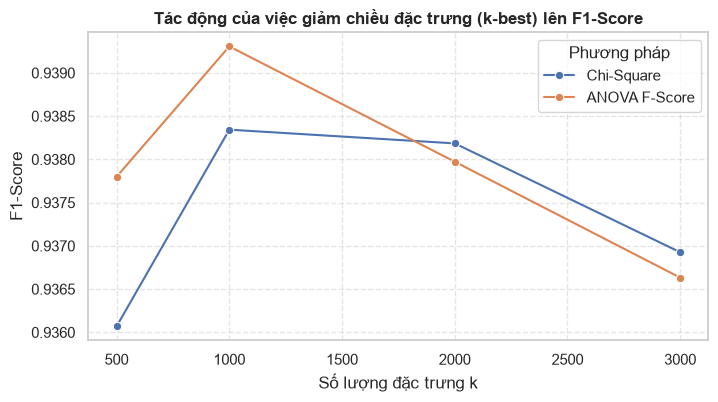

In [17]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=df_fs_eval, x='Số lượng đặc trưng k', y='F1-Score', hue='Phương pháp', marker='o')
plt.title("Tác động của việc giảm chiều đặc trưng (k-best) lên F1-Score", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Hyperparameter Tuning
Với các thuật toán TfidfVectorizer, FeatureSelector, và model SVM, có nhiều siêu tham số có thể được chọn. Ở khối dưới, chúng em áp dụng RandomizedSearchCV với kiểm định chéo phân tầng 5 lớp (Stratified 5-Fold CV) để truy tìm các siêu tham số (Hyperparamter) tốt nhất để áp dụng cho bài toán. RandomizedSearchCV là một thuật toán chọn ngẫu nhiên tổ hợp các siêu tham số, so sánh và chọn ra tổ hợp tốt nhất để áp dụng cho bài toán hiện tại.

In [18]:
# Subsample raw text to keep search fast and practical
X_sub_raw, _, y_sub, _ = train_test_split(
    X_train_raw, y_train, train_size=4000, random_state=42, stratify=y_train
)

# Unified Pipeline: Vectorizer -> Feature Selector -> Classifier
full_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('selector', SelectKBest(score_func=chi2)),
    ('svm', SVC(random_state=42, max_iter=3000))
])

# Parameter distributions across the entire pipeline
param_distributions = {
    # 1. Vectorizer Hyperparameters
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__max_features': [3000, 5000],
    'tfidf__sublinear_tf': [True, False],
    
    # 2. Feature Selection Hyperparameters
    'selector__k': [1000, 2000, 3000],
    
    # 3. Model Hyperparameters
    'svm__kernel': ['linear', 'sigmoid', 'rbf'],
    'svm__C': [0.1, 0.5, 1.0, 5.0, 10.0],
    'svm__gamma': ['scale', 'auto', 0.01, 0.1],
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Set budget to 15 iterations (15 * 3 = 45 total fits)
random_search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    cv=cv_strat,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)

random_search.fit(X_sub_raw, y_sub)

df_cv_results = pd.DataFrame(random_search.cv_results_)

print(f"Optimal Parameters: {random_search.best_params_}")
print(f"Best CV F1-Score: {random_search.best_score_:.4f}\n")

# Display top configurations sorted by F1-Score alongside execution time
top_models = df_cv_results[[
    'param_svm__kernel',
    'param_svm__C',
    'param_selector__k',
    'param_tfidf__ngram_range',
    'mean_test_score',
    'mean_fit_time'
]].sort_values(by='mean_test_score', ascending=False).reset_index(drop=True)

display(top_models.head(5))

Optimal Parameters: {'tfidf__sublinear_tf': False, 'tfidf__ngram_range': (1, 1), 'tfidf__max_features': 5000, 'svm__kernel': 'sigmoid', 'svm__gamma': 'scale', 'svm__C': 0.5, 'selector__k': 2000}
Best CV F1-Score: 0.9320



,param_svm__kernel,param_svm__C,param_selector__k,param_tfidf__ngram_range,mean_test_score,mean_fit_time
0,sigmoid,0.5,2000,"(1, 1)",0.931988,1.163745
1,linear,1.0,1000,"(1, 1)",0.927124,0.792569
2,linear,0.5,2000,"(1, 1)",0.923715,1.258776
3,linear,0.5,1000,"(1, 1)",0.923442,1.154214
4,linear,0.5,2000,"(1, 1)",0.923210,1.404000


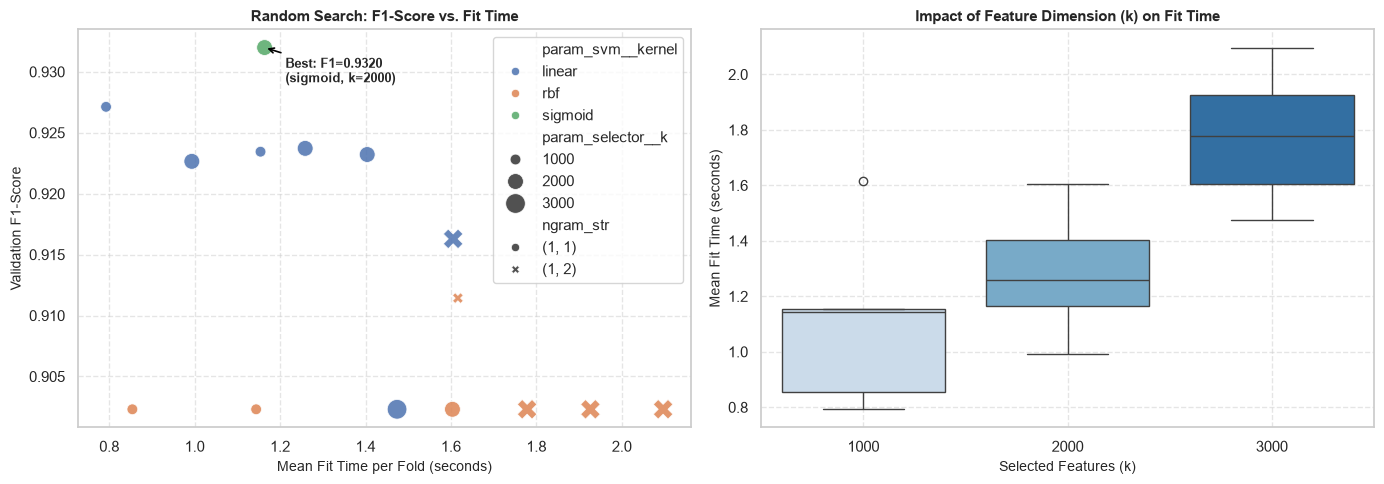

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

results_df = pd.DataFrame(random_search.cv_results_)

plot_df = results_df[[
    'param_svm__kernel',
    'param_svm__C',
    'param_selector__k',
    'param_tfidf__ngram_range',
    'mean_test_score',
    'mean_fit_time',
]].copy()

plot_df['param_svm__C'] = plot_df['param_svm__C'].astype(float)
plot_df['param_selector__k'] = plot_df['param_selector__k'].astype(int)
plot_df['ngram_str'] = plot_df['param_tfidf__ngram_range'].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Efficiency Frontier (F1-Score vs. Training Time per candidate)
sns.scatterplot(
    data=plot_df,
    x='mean_fit_time',
    y='mean_test_score',
    hue='param_svm__kernel',
    style='ngram_str',
    size='param_selector__k',
    sizes=(60, 200),
    alpha=0.85,
    ax=axes[0]
)
axes[0].set_title('Random Search: F1-Score vs. Fit Time', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Mean Fit Time per Fold (seconds)', fontsize=10)
axes[0].set_ylabel('Validation F1-Score', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Annotate the best configuration found
best_idx = plot_df['mean_test_score'].idxmax()
best_row = plot_df.loc[best_idx]
axes[0].annotate(
    f"Best: F1={best_row['mean_test_score']:.4f}\n({best_row['param_svm__kernel']}, k={best_row['param_selector__k']})",
    xy=(best_row['mean_fit_time'], best_row['mean_test_score']),
    xytext=(15, -25),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
    fontsize=9,
    fontweight='bold'
)

# Panel 2: Impact of Feature Count (k) on Training Duration
sns.boxplot(
    data=plot_df,
    x='param_selector__k',
    y='mean_fit_time',
    palette='Blues',
    ax=axes[1]
)
axes[1].set_title('Impact of Feature Dimension (k) on Fit Time', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Selected Features (k)', fontsize=10)
axes[1].set_ylabel('Mean Fit Time (seconds)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Ensemble Learning

Thay vì chỉ sử dụng một mô hình đơn thuần, ta có thể sử dụng nhiều mô hình, sau đó tổng hợp kết quả của chúng để tìm được dự đoán đúng nhất. Chúng em so sánh hai phương pháp Ensemble Learning sau: 

1. Bagging: Giảm phương sai bằng cách huấn luyện song song nhiều mô hình trên các tập con mẫu.
2. Boosting: Giảm độ chệch bằng cách huấn luyện tuần tự để sửa lỗi của mô hình trước.

In [20]:
ensemble_models = {
    'Bagging': BaggingClassifier(
        estimator=LinearSVC(C=0.5, random_state=42),
        n_estimators=10,
        max_samples=0.8,
        random_state=42,
        n_jobs=-1
    ),
    'AdaBoostClassifier': AdaBoostClassifier(n_estimators=50, random_state=42)
}

ensemble_results = []
for name, model in ensemble_models.items():
    model.fit(X_train_vec, y_train)
    preds = model.predict(X_test_vec)
    ensemble_results.append({
        'Mô hình Ensemble': name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds)
    })

df_ens_eval = pd.DataFrame(ensemble_results)
display(df_ens_eval)

,Mô hình Ensemble,Accuracy,F1-Score
0,Bagging,0.893359,0.936862
1,AdaBoostClassifier,0.841209,0.911296


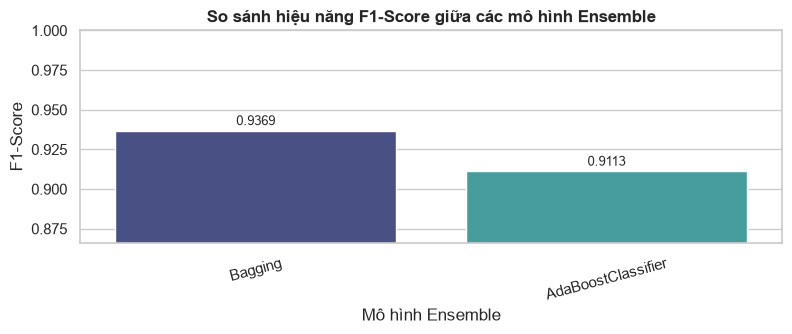

In [21]:
plt.figure(figsize=(8, 3.5))
ax = sns.barplot(data=df_ens_eval, x='Mô hình Ensemble', y='F1-Score', palette='mako')
plt.ylim(df_ens_eval['F1-Score'].min() * 0.95, 1.0)
plt.title("So sánh hiệu năng F1-Score giữa các mô hình Ensemble", fontsize=12, fontweight='bold')
plt.xticks(rotation=15)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.show()

# Kết quả

Sử dụng Tokenizer Tfidf, ứng dụng Feature Selection, Ensemble Learning cùng với các siêu tham số tìm được để tạo dựng một model SVM hoàn chỉnh cuối cùng.

-> Reduced training shape: (18788, 2000)
-> Model converged in 17.57 seconds
-> Total execution time: 25.17 seconds

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

Negative (0)       0.78      0.57      0.66       828
Positive (1)       0.91      0.96      0.94      3870

    accuracy                           0.90      4698
   macro avg       0.84      0.77      0.80      4698
weighted avg       0.89      0.90      0.89      4698



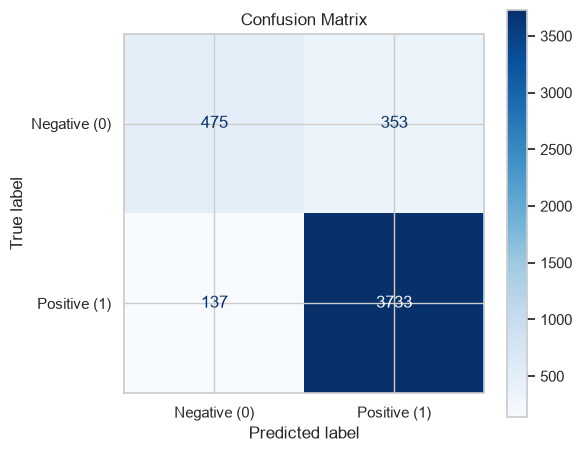

In [22]:
start_total = dt.datetime.now()

# 1. Extract best parameters
best_params = random_search.best_params_
tfidf_params = {k.replace('tfidf__', ''): v for k, v in best_params.items() if k.startswith('tfidf__')}
selector_params = {k.replace('selector__', ''): v for k, v in best_params.items() if k.startswith('selector__')}
svm_params = {k.replace('svm__', ''): v for k, v in best_params.items() if k.startswith('svm__')}

# 2. Vectorization
vectorizer = TfidfVectorizer(**tfidf_params)
X_train_vec = vectorizer.fit_transform(X_train_raw)
X_test_vec = vectorizer.transform(X_test_raw)

# 3. Selection & Index Sorting Fix
selector = SelectKBest(score_func=chi2, **selector_params)
X_train_selected = selector.fit_transform(X_train_vec, y_train)
X_test_selected = selector.transform(X_test_vec)

# PREVENT READ-ONLY MEMMAP ERROR
X_train_selected.sort_indices()
X_test_selected.sort_indices()

print(f"-> Reduced training shape: {X_train_selected.shape}")

# 4. Fit Stacking Classifier
t_train = dt.datetime.now()

model = BaggingClassifier(
    estimator=SVC(**svm_params),
    n_estimators=10,
    max_samples=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_selected, y_train)
train_time = (dt.datetime.now() - t_train).total_seconds()
print(f"-> Model converged in {train_time:.2f} seconds")

# 5. Evaluate
y_pred = model.predict(X_test_selected)
total_elapsed = (dt.datetime.now() - start_total).total_seconds()
print(f"-> Total execution time: {total_elapsed:.2f} seconds\n")

print('=' * 60)
print('FINAL CLASSIFICATION REPORT')
print('=' * 60)
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)']))

cm = confusion_matrix(y_test, y_pred)
labels = ['Negative (0)', 'Positive (1)']

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", ax=ax, values_format="d")
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()